In [ ]:
# LAB EDA Bivariate Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, chi2
from scipy.stats import pearsonr
import statsmodels.api as sm

In [2]:
# Load the dataset
file_path = 'amz_uk_price_prediction_dataset.csv'
data = pd.read_csv(file_path)

# Display the first few rows of the dataset
data.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories

In [3]:
# Crosstab Analysis

# Create a crosstab between product category and best-seller status
crosstab = pd.crosstab(data['category'], data['isBestSeller'])

# Check the structure of the crosstab
print(crosstab.head())

# Adjust the proportion calculation based on unique values found
if 'Yes' in data['isBestSeller'].unique():
    crosstab['Proportion'] = crosstab['Yes'] / (crosstab['Yes'] + crosstab['No'])
else:
    crosstab


isBestSeller                   False  True 
category                                   
3D Printers                      247      1
3D Printing & Scanning          4065      2
Abrasive & Finishing Products    245      5
Action Cameras                  1696      1
Adapters                         251      3


In [4]:
# Statistical Tests

chi2_stat, p, dof, ex = chi2_contingency(crosstab.iloc[:, :-1])

print(f"Chi2 Stat: {chi2_stat}, p-value: {p}")


Chi2 Stat: 0.0, p-value: 1.0


In [5]:
# Cramér's V

def cramers_v(chi2, n, r, k):
    if n == 0 or min(r, k) == 1:
        return 0  # Return 0 to avoid division by zero
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cramers_v_value = cramers_v(chi2_stat, len(data), len(crosstab.index), len(crosstab.columns)-1)
print(f"Cramér's V: {cramers_v_value}")



Cramér's V: 0


In [ ]:
# Visualizations

crosstab.plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Best-Seller Status by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Count')
plt.legend(title='Best-Seller Status')
plt.show()



In [ ]:
# PART 2

In [6]:
#  Removing Outliers in Product Prices

Q1 = data['price'].quantile(0.25)
Q3 = data['price'].quantile(0.75)
IQR = Q3 - Q1

filter = (data['price'] >= (Q1 - 1.5 * IQR)) & (data['price'] <= (Q3 + 1.5 * IQR))
data_no_outliers = data.loc[filter]

print(data_no_outliers.describe())  # Check the data after removing outliers


                uid         stars       reviews         price  \
count  2.115963e+06  2.115963e+06  2.115963e+06  2.115963e+06   
mean   1.374141e+06  2.275402e+00  5.205211e+02  2.340827e+01   
std    8.169684e+05  2.193863e+00  6.233481e+03  2.051335e+01   
min    1.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
25%    6.589495e+05  0.000000e+00  0.000000e+00  9.130000e+00   
50%    1.347315e+06  3.400000e+00  1.000000e+00  1.599000e+01   
75%    2.067576e+06  4.400000e+00  7.500000e+01  2.999000e+01   
max    2.828593e+06  5.000000e+00  1.356658e+06  9.999000e+01   

       boughtInLastMonth  
count       2.115963e+06  
mean        2.970697e+01  
std         2.579316e+02  
min         0.000000e+00  
25%         0.000000e+00  
50%         0.000000e+00  
75%         0.000000e+00  
max         5.000000e+04  


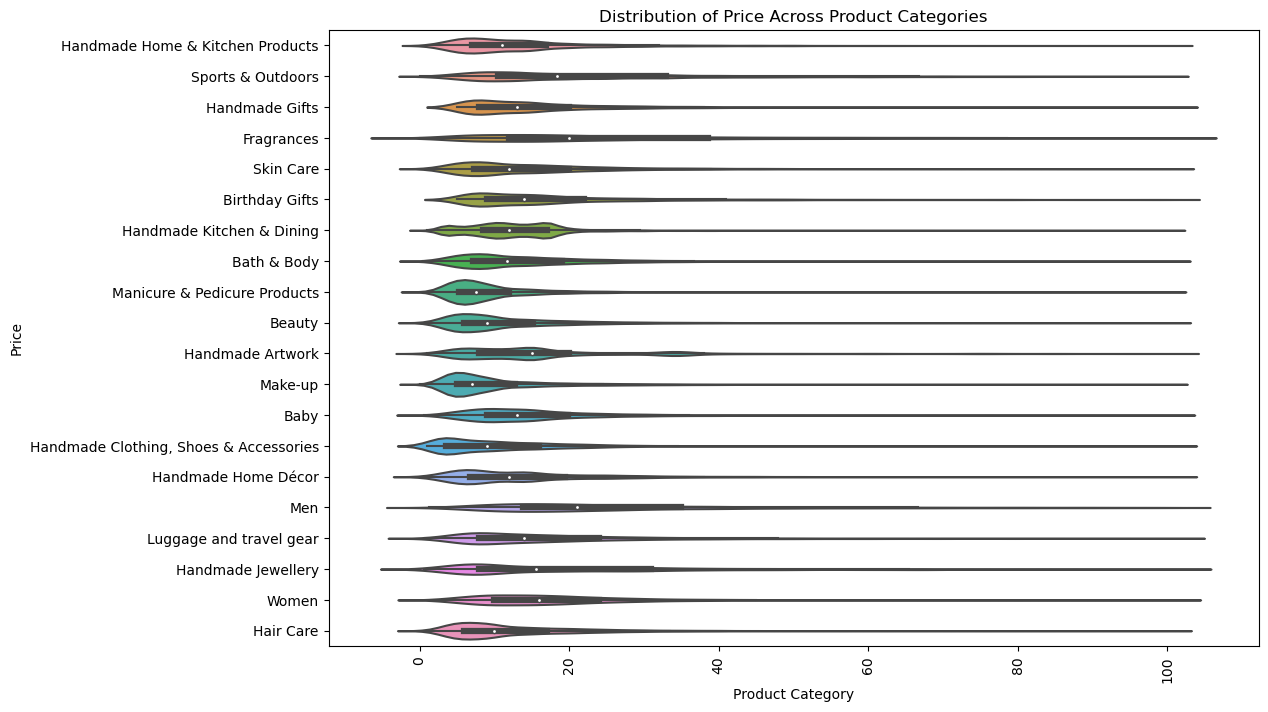

In [7]:
# Violin Plots

top_20_categories = data_no_outliers['category'].value_counts().nlargest(20).index
filtered_data = data_no_outliers[data_no_outliers['category'].isin(top_20_categories)]

plt.figure(figsize=(12, 8))
sns.violinplot(x='price', y='category', data=filtered_data)
plt.title('Distribution of Price Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.xticks(rotation=90)
plt.show()


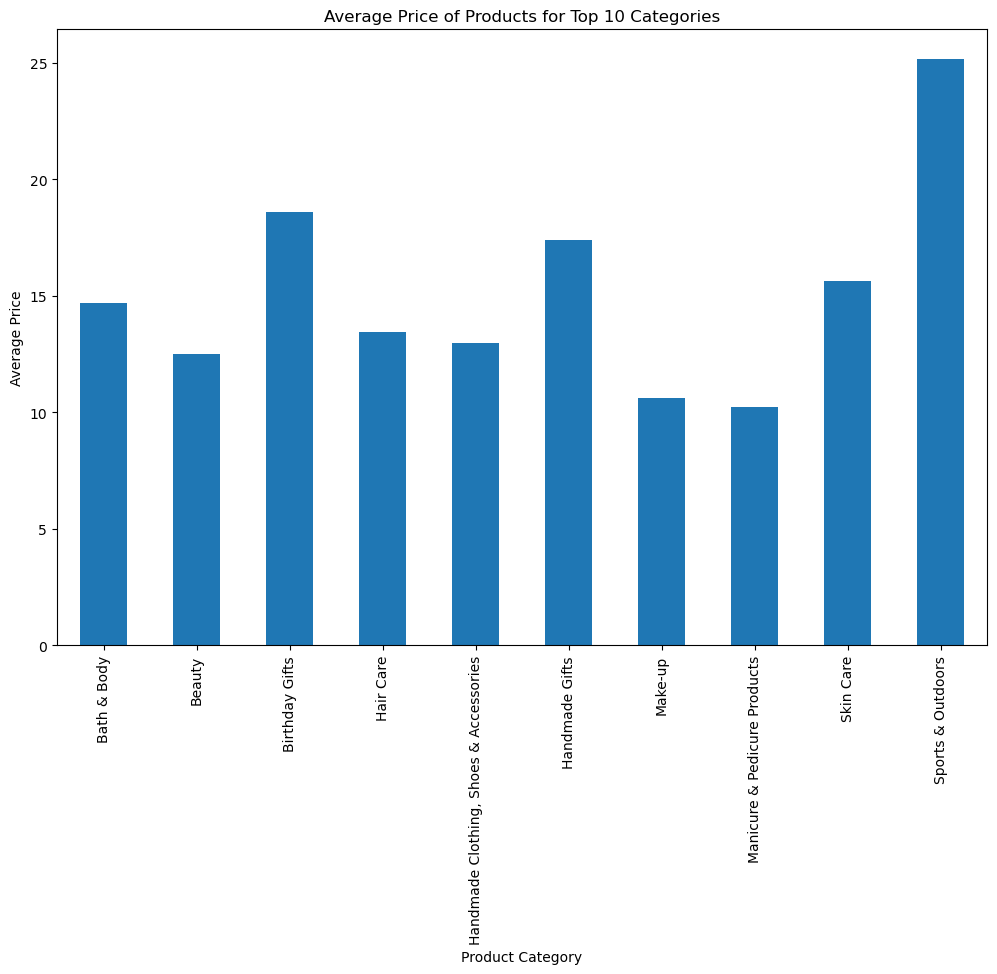

In [8]:
# Bar Charts

top_10_categories = data_no_outliers['category'].value_counts().nlargest(10).index
avg_price = data_no_outliers[data_no_outliers['category'].isin(top_10_categories)].groupby('category')['price'].mean()

avg_price.plot(kind='bar', figsize=(12, 8))
plt.title('Average Price of Products for Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.show()


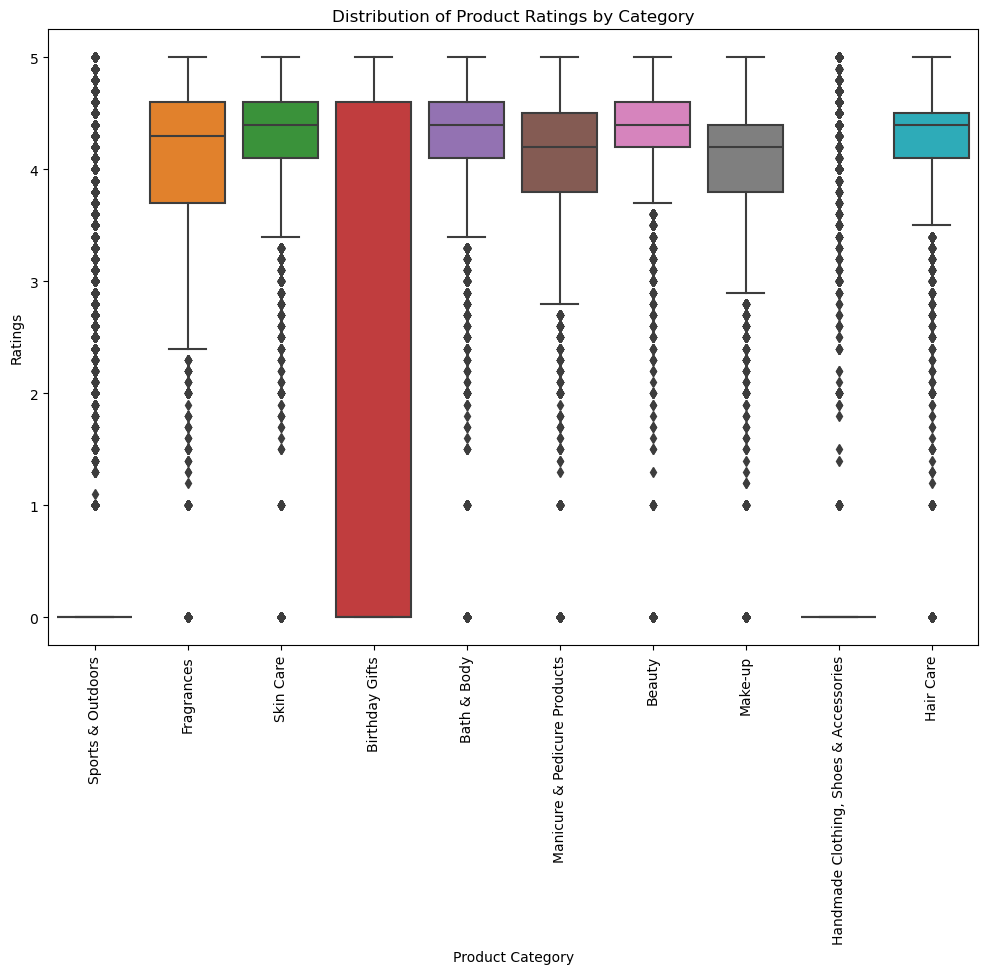

In [9]:
# Box Plots

top_10_categories = data['category'].value_counts().nlargest(10).index
filtered_data = data[data['category'].isin(top_10_categories)]

plt.figure(figsize=(12, 8))
sns.boxplot(x='category', y='stars', data=filtered_data)
plt.title('Distribution of Product Ratings by Category')
plt.xlabel('Product Category')
plt.ylabel('Ratings')
plt.xticks(rotation=90)
plt.show()


In [ ]:
# PART 3

In [10]:
# Correlation Coefficients

corr, _ = pearsonr(data_no_outliers['price'], data_no_outliers['stars'])
print(f'Correlation coefficient between price and stars: {corr}')


Correlation coefficient between price and stars: -0.07767299878181383


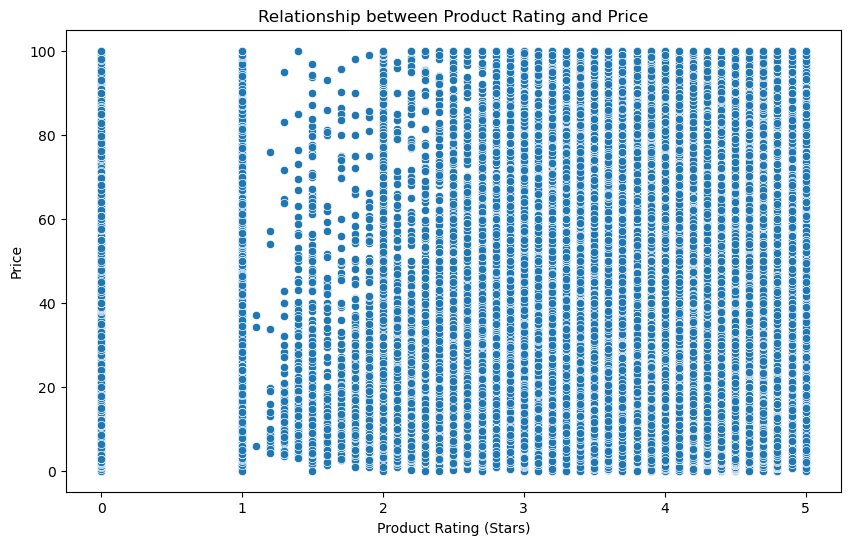

In [11]:
# Visualizations

plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=data_no_outliers)
plt.title('Relationship between Product Rating and Price')
plt.xlabel('Product Rating (Stars)')
plt.ylabel('Price')
plt.show()


   uid  stars  reviews  price  boughtInLastMonth
0    1    4.7    15308  21.99                  0
1    2    4.7    98099  23.99                  0
2    3    4.7    15308  21.99                  0
3    4    4.7     7205  31.99                  0
4    5    4.6     1881  17.99                  0


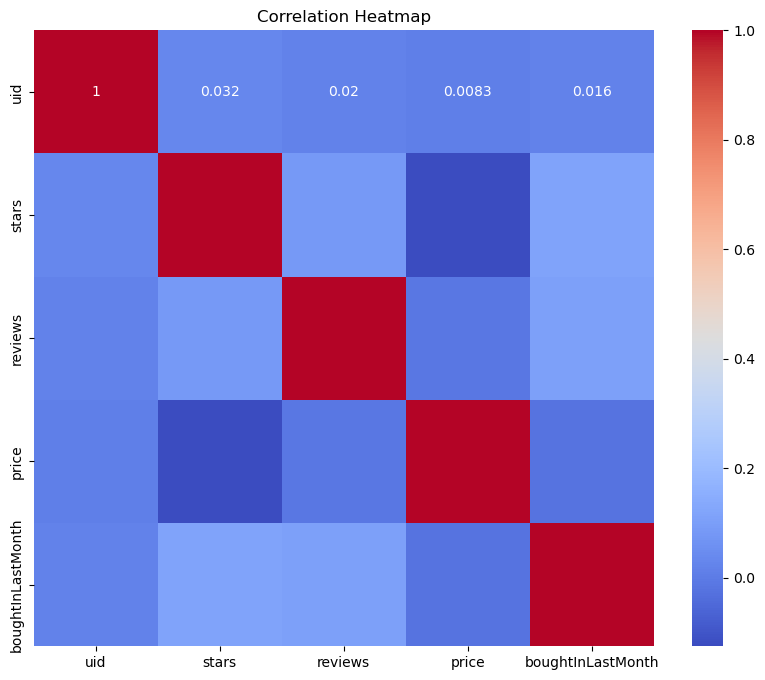

In [12]:
# Filter only numeric columns
numeric_data = data.select_dtypes(include=[np.number])

# Display the first few rows of the numeric dataset
print(numeric_data.head())

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Create a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

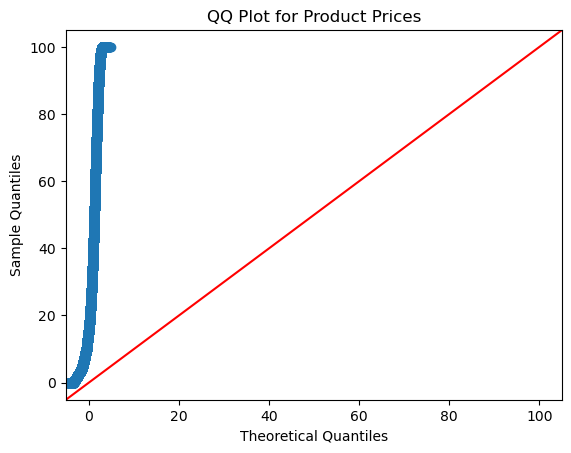

In [13]:
# Examine

sm.qqplot(data_no_outliers['price'], line ='45')
plt.title('QQ Plot for Product Prices')
plt.show()
